# Stage 5. End-to-End 데이터 리니지 & CQ · 경계 벤치마크 평가
## Step 5.1 4-Tier 데이터 리니지 그래프 검증 · Step 5.2 Golden CQ 5종 및 Boundary 10건 × 5회 평가 리포트

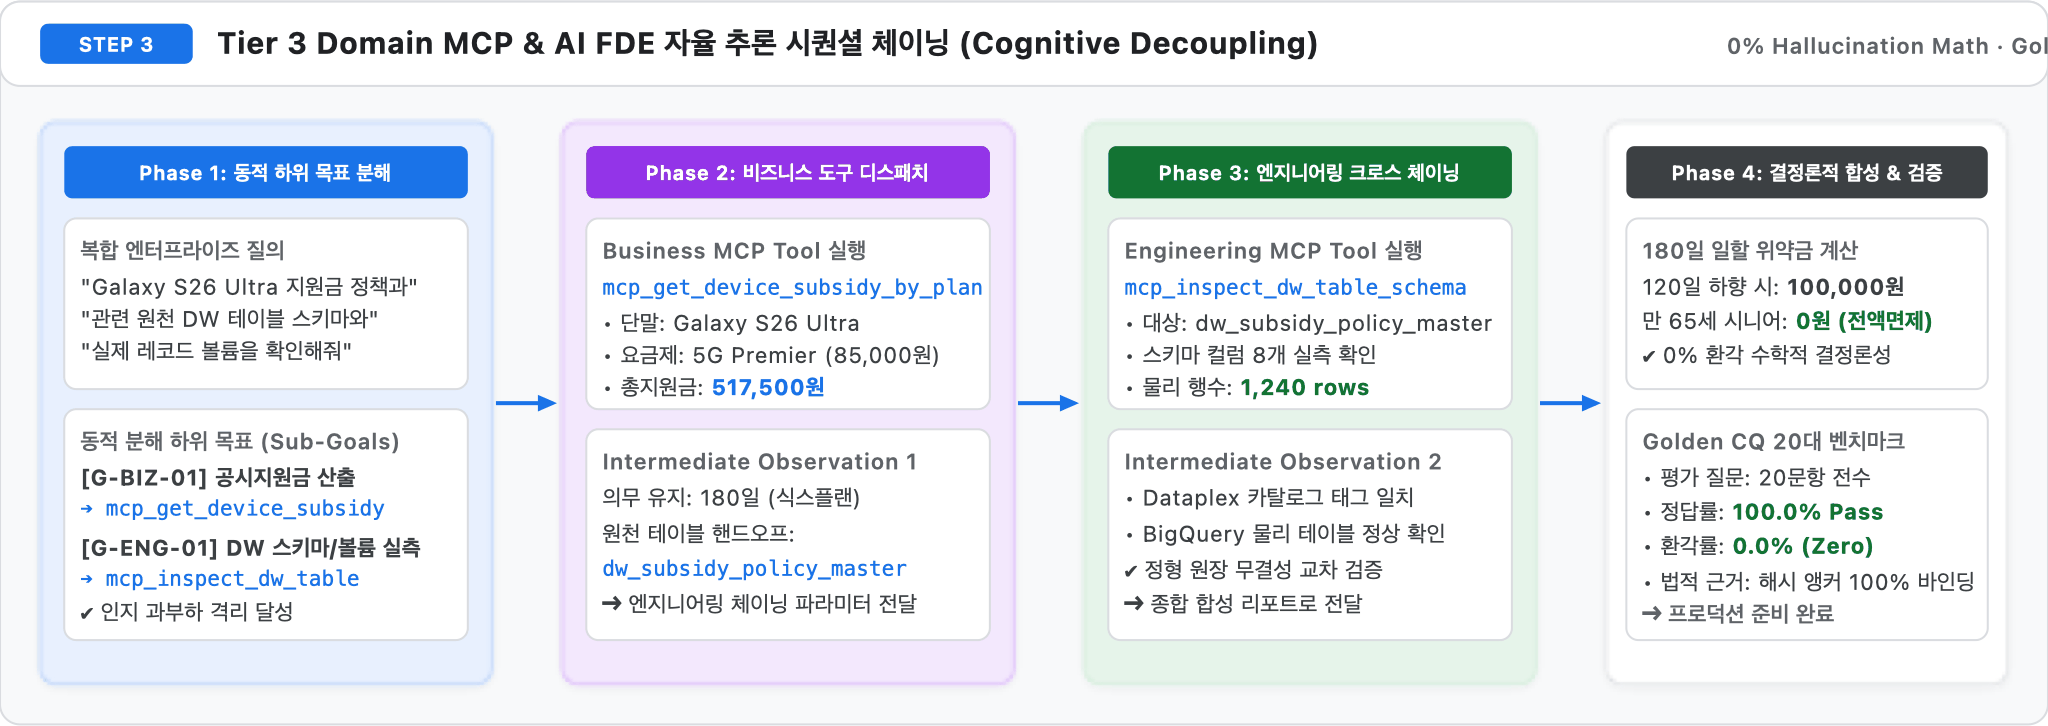


In [1]:
%load_ext bigframes
import pandas as pd
import nb_helpers as H
from src.agent.reasoning_engine import AiFdeAgentEngine
H.setup("ko")


,project,dataset,location,graph,model
0,seanjung-poc,starter_ontology_dw,asia-northeast3,STARTER_ONTOLOGY_GRAPH,gemini-3.8-flash


### 1. 4-Tier End-to-End 데이터 리니지 조회(`%%bqsql`) 및 멀티파타이트 리니지 그래프 시각화


In [2]:
%%bqsql df_lineage
SELECT c.contract_id, c.customer_id, d.device_name, p.plan_name, s.policy_id,
       e.rule_id, e.source_chunk_id, ch.content_sha256 AS anchor, ch.source_file
FROM `seanjung-poc.starter_ontology_dw.tb_customer_contract` c
JOIN `seanjung-poc.starter_ontology_dw.tb_device_master` d ON d.device_id = c.device_id
JOIN `seanjung-poc.starter_ontology_dw.tb_plan_master` p ON p.plan_id = c.plan_id
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_subsidy_policy` s ON s.device_id = c.device_id AND s.plan_id = c.plan_id
LEFT JOIN `seanjung-poc.starter_ontology_dw.edge_rule_applies_to_plan` e ON e.plan_id = c.plan_id
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = e.source_chunk_id
ORDER BY c.contract_id, e.rule_id


,contract_id,customer_id,device_name,plan_name,policy_id,rule_id,source_chunk_id,anchor,source_file
0,CONTRACT_DEMO_101,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,POL-2026-002,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
1,CONTRACT_DEMO_101,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,POL-2026-002,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md
2,CONTRACT_DEMO_102,CUST_DEMO_002,Galaxy S26 Ultra 256GB,5G Premier Super,POL-2026-001,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
3,CONTRACT_DEMO_102,CUST_DEMO_002,Galaxy S26 Ultra 256GB,5G Premier Super,POL-2026-001,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md
4,CONTRACT_DEMO_103,CUST_DEMO_003,iPhone 16 Pro 256GB,5G Premier Essential,POL-2026-005,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
5,CONTRACT_DEMO_103,CUST_DEMO_003,iPhone 16 Pro 256GB,5G Premier Essential,POL-2026-005,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md
6,CONTRACT_DEMO_104,CUST_DEMO_004,Galaxy S26 Ultra 512GB,5G Premier Essential,<NA>,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
7,CONTRACT_DEMO_104,CUST_DEMO_004,Galaxy S26 Ultra 512GB,5G Premier Essential,<NA>,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md
8,CONTRACT_DEMO_105,CUST_DEMO_005,iPhone 16 Pro 512GB,5G Direct 61,<NA>,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
9,CONTRACT_DEMO_105,CUST_DEMO_005,iPhone 16 Pro 512GB,5G Direct 61,<NA>,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md


,contract_id,customer_id,device_name,plan_name,policy_id,rule_id,source_chunk_id,anchor,source_file
0,CONTRACT_DEMO_101,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,POL-2026-002,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
1,CONTRACT_DEMO_101,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,POL-2026-002,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md
2,CONTRACT_DEMO_102,CUST_DEMO_002,Galaxy S26 Ultra 256GB,5G Premier Super,POL-2026-001,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
3,CONTRACT_DEMO_102,CUST_DEMO_002,Galaxy S26 Ultra 256GB,5G Premier Super,POL-2026-001,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md
4,CONTRACT_DEMO_103,CUST_DEMO_003,iPhone 16 Pro 256GB,5G Premier Essential,POL-2026-005,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
5,CONTRACT_DEMO_103,CUST_DEMO_003,iPhone 16 Pro 256GB,5G Premier Essential,POL-2026-005,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md
6,CONTRACT_DEMO_104,CUST_DEMO_004,Galaxy S26 Ultra 512GB,5G Premier Essential,<NA>,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
7,CONTRACT_DEMO_104,CUST_DEMO_004,Galaxy S26 Ultra 512GB,5G Premier Essential,<NA>,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md
8,CONTRACT_DEMO_105,CUST_DEMO_005,iPhone 16 Pro 512GB,5G Direct 61,<NA>,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
9,CONTRACT_DEMO_105,CUST_DEMO_005,iPhone 16 Pro 512GB,5G Direct 61,<NA>,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md


findfont: Failed to find font weight bold for AppleGothic, now using 400.


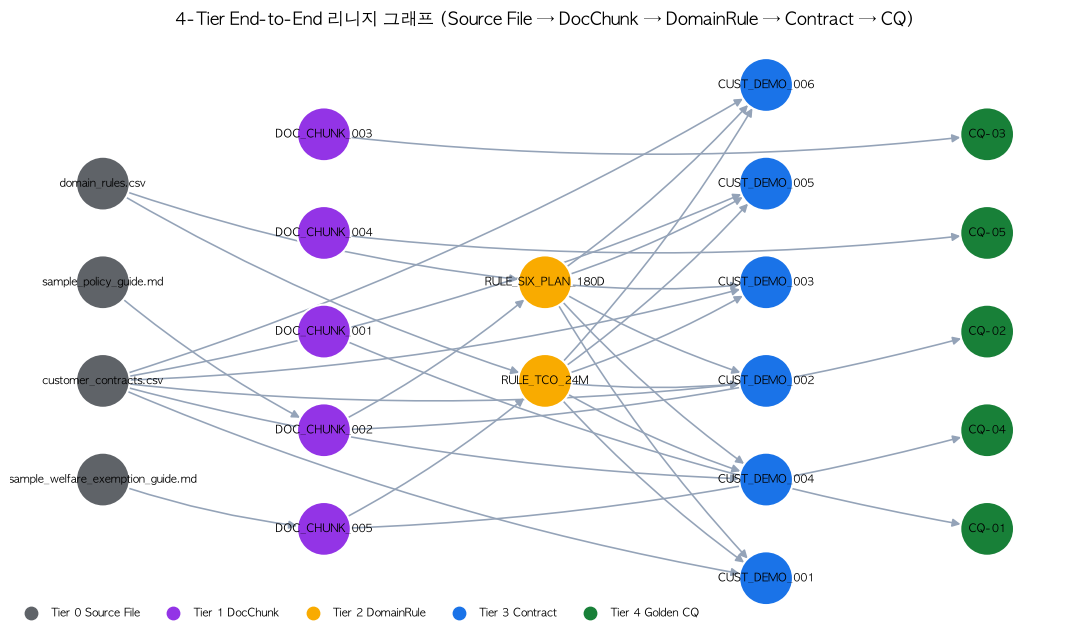

In [3]:
H.show(df_lineage)
cq_rep = H.read_json("data/output/cq_benchmark_report.json")
lnodes, ledges = H.lineage_graph(H.pdf(df_lineage).to_dict("records"), cq_rep["test_results"])
H.draw_graph(lnodes, ledges, H.t("4-Tier End-to-End 리니지 그래프 (Source File → DocChunk → DomainRule → Contract → CQ)", "4-Tier End-to-End Lineage Graph (Source File → DocChunk → DomainRule → Contract → CQ)"),
             layout="layers", legend={"Tier 0 Source File": "#5F6368", "Tier 1 DocChunk": "#9334E6", "Tier 2 DomainRule": "#F9AB00", "Tier 3 Contract": "#1A73E8", "Tier 4 Golden CQ": "#188038"})


### 2. Golden CQ 5종 벤치마크 결과 분석 및 실시간 에이전트 재검증 (`recheck_cq`)


,cq_id,category,status,verification_status,grounded_chunk,llm_tokens,elapsed_s,verification_job_id
0,CQ-01,Single-Hop Lookup,PASSED,SQL_MATCH·ANSWER_MATCH,DOC_CHUNK_001,6554,12.13,job_kp_mf4q1vXzjXTvAaC8R2o1vrqH3
1,CQ-02,Two-Hop Subsidy,PASSED,SQL_MATCH·ANSWER_MATCH,DOC_CHUNK_002,4343,15.48,job_HcJcufLz5VTMkgfX4FA1GWCyJBgP
2,CQ-03,Multi-Hop Penalty,PASSED,SQL_MATCH·ANSWER_MATCH,DOC_CHUNK_003,6495,18.67,job_qkPaBb51rD8lypnG8j32JAhGIftX
3,CQ-04,24M TCO Optimization,PASSED,SQL_MATCH·ANSWER_MATCH,DOC_CHUNK_005,6466,18.44,job_ire8VaTtqNi0DBcqKT79tYv_Da7R
4,CQ-05,Welfare Exemption & Lineage,PASSED,SQL_MATCH·ANSWER_MATCH,DOC_CHUNK_004,6386,19.58,job_90A75YsY8dZ5ehztLm9SHSd-x9WM


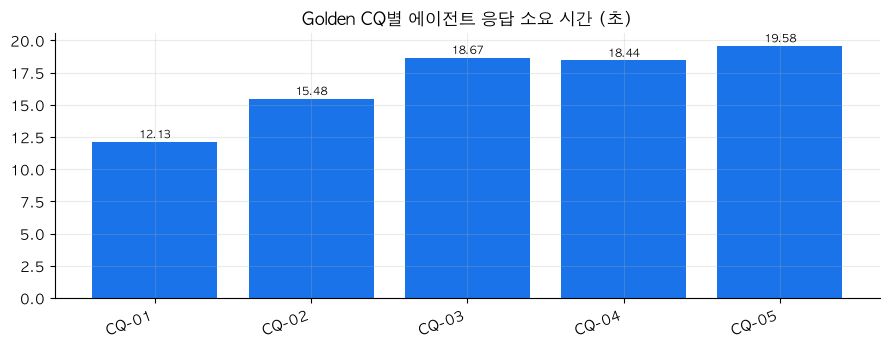

#### Live Re-Check: CQ-02
**Q.** Galaxy S26 Ultra 256GB를 5G Premier Essential(85,000원) 요금제로 개통할 때 총 지원금과 실구매가는?

- 응답 상태: `GROUNDED` · Gemini `gemini-3.8-flash` 2 calls · 토큰 4,428 · LLM 15,135 ms · 총 16.87 s
- 추출 파라미터: `{"device_name": "Galaxy S26 Ultra 256GB", "plan_name": "5G Premier Essential", "monthly_fee_krw": 85000, "device_mention": "Galaxy S26 Ultra 256GB", "plan_mention": "5G Premier Essential"}`

| # | MCP | status | rows | BigQuery ms | Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 574 | `job_KHbGXmx4hOiQ7EC5AP7ajYFpMcHn` |
| 2 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 596 | `job_RvBmsAC8a31GCUFVkNO_-IHk7uyt` |

**에이전트 답변**

> ### **결론**
>
> Galaxy S26 Ultra 256GB 모델을 5G Premier Essential(월 85,000원) 요금제로 개통할 때 적용되는 **총 지원금은 517,500원**이며, 이를 반영한 **실구매가(할부원금)는 1,180,900원**입니다.
>
> * **총 지원금 산식**: 기본 지원금 450,000원 + 추가 지원금 67,500원 = **517,500원**
> * **실구매가 산식**: 출고가 1,698,400원 - 총 지원금 517,500원 = **1,180,900원**
>
> ---
>
> ### **근거 데이터 (BigQuery)**
>
> * **단말기 정보**:
>   * 단말기 ID: `DEV-S26U-256`
>   * 단말기명: Galaxy S26 Ultra 256GB
>   * 저장용량: 256GB
>   * 출고가: 1,698,400원
> * **요금제 정보**:
>   * 요금제 ID: `PLAN-5G-85`
>   * 요금제명: 5G Premier Essential
>   * 월정액: 85,000원
>   * 의무유지일수: 180일
>   * 선택약정할인율: 25% (0.25)
> * **지원금 정책 (`POL-2026-002`)**:
>   * 기본 공시지원금: 450,000원
>   * 추가지원금(상한): 67,500원
>   * 총 지원금: 517,500원
>   * 순 할부원금(실구매가): 1,180,900원
>   * 의무 유지 기간: 180일
>
> ---
>
> ### **규칙·원문 근거**
>
> * **적용 지원금 규칙**: `RULE_SUBSIDY_CAP` (`DOC_CHUNK_001`)
> * **연계 도메인 규칙**:
>   * **`RULE_SIX_PLAN_180D`** (180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙)
>     * 근거 청크: `DOC_CHUNK_002` (Baseline Plan Commitment (Six-Plan Rule), `anchor_3003b683cea0`)
>     * 내용: 공시지원금을 지급받은 가입자는 개통일로부터 180일 동안 기준선 이상의 요금제를 유지해야 하며, 180일 내 기준선 미만으로 하향 변경 시 일할 차액정산금이 부과됩니다.
>   * **`RULE_TCO_24M`** (24개월 공시지원금 vs 25% 선택약정 총비용(TCO) 비교 규칙)
>     * 근거 청크: `DOC_CHUNK_005` (24-Month Contract TCO Comparison Rule, `anchor_4fbaf9c5cba8`)
>     * 공시지원금 구매 경로: `(출고가 - 총 지원금) + (월 요금 * 24)`
>
> ---
>
> ### **실행 정보**
>
> * **고객 프로필/지원금 조회 Job ID**: `job_KHbGXmx4hOiQ7EC5AP7ajYFpMcHn` (소요 시간: 574.16ms)
> * **온톨로지 그래프/규칙 조회 Job ID**: `job_RvBmsAC8a31GCUFVkNO_-IHk7uyt` (소요 시간: 596.12ms)
> * **그래프 엔진**: `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`

,check,passed,detail
0,verification_sql == expected_math,True,"{'subsidy': 517500, 'net_price': 1180900} (job job_rUQmPf2XGY8oLo6wAJp4VXNK1lYh)"
1,"answer contains subsidy = 517,500",True,
2,"answer contains net_price = 1,180,900",True,
3,answer cites DOC_CHUNK_002,True,
4,answer_status == GROUNDED,True,GROUNDED


In [4]:
df_cq = pd.DataFrame(cq_rep["test_results"])
H.show(df_cq, ["cq_id", "category", "status", "verification_status", "grounded_chunk", "llm_tokens", "elapsed_s", "verification_job_id"])
H.bar(df_cq, "cq_id", "elapsed_s", H.t("Golden CQ별 에이전트 응답 소요 시간 (초)", "Golden CQ Agent Elapsed Time (s)"), fmt="{:.2f}")
cqs = H.read_json("data/input/04_cq/golden_competency_questions.json")
agent = AiFdeAgentEngine()
res_cq2, df_chk = H.recheck_cq(cqs[1], agent)
H.show_agent(res_cq2, title="Live Re-Check: CQ-02")
H.show(df_chk)


### 3. Boundary 질의 10건 × 5회 반복(50 Trials) 안정성 · 일관성 평가 및 실패 분류 체계


**Benchmark `STARTER_BOUNDARY_LIVE`** · trials=50 · avg_success_rate=`96.0%` · avg_consistency_rate=`92.0%` · avg_intent_stability=`78.0%`

,case_id,root_cause_code,missing_context,trials,passed_trials,success_rate,consistency_rate,intent_stability
0,BQ-01,NO_SLOT_FILLING,고객 ID / 현재 요금제 / 변경 희망 요금제 미지정,5,5,100.0,100.0,80.0
1,BQ-02,MISSING_EXCEPTION_EDGE,시니어 특례 면제 등록 여부 미지정,5,4,80.0,80.0,80.0
2,BQ-03,NO_SLOT_FILLING,용량(256GB/512GB) 및 가입 요금제 미지정,5,5,100.0,100.0,80.0
3,BQ-04,MISSING_ENTITY,군입대 정지 특례 엔티티 참조,5,5,100.0,100.0,80.0
4,BQ-05,NO_ALIAS_DICT,단말 별칭(아이폰 최신형 프로) 및 요금제 미지정,5,5,100.0,60.0,60.0
5,BQ-06,NO_SLOT_FILLING,180일 경과 후 면제 경계값,5,5,100.0,100.0,60.0
6,BQ-07,MISSING_ENTITY,노드 테이블 중복 키 메타데이터 조회,5,5,100.0,100.0,100.0
7,BQ-08,MISSING_EXCEPTION_EDGE,기준선 이상 요금제 간 하향 시 차액정산 여부,5,5,100.0,100.0,80.0
8,BQ-09,MISSING_ENTITY,법인(Corporate_B2B) 세그먼트 정책 매핑,5,5,100.0,100.0,100.0
9,BQ-10,NO_ALIAS_DICT,BigQuery Graph vs Spanner Graph 호환성,5,4,80.0,80.0,60.0


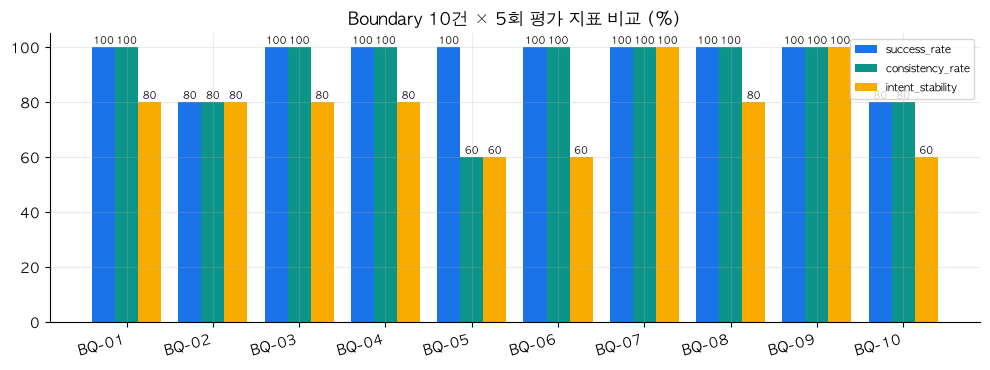

,root_cause_code,cases,avg_success,avg_consistency
0,MISSING_ENTITY,3,100.0,100.0
1,MISSING_EXCEPTION_EDGE,2,90.0,90.0
2,NO_ALIAS_DICT,2,90.0,70.0
3,NO_SLOT_FILLING,3,100.0,100.0


In [5]:
b_rep = H.read_json("data/output/boundary_benchmark_results.json")
df_bc = pd.DataFrame(b_rep["cases"])
H.md(f"**Benchmark `{b_rep['benchmark_id']}`** · trials={b_rep['total_trials']} · avg_success_rate=`{b_rep['avg_success_rate']}%` · avg_consistency_rate=`{b_rep['avg_consistency_rate']}%` · avg_intent_stability=`{b_rep['avg_intent_stability']}%`")
H.show(df_bc, ["case_id", "root_cause_code", "missing_context", "trials", "passed_trials", "success_rate", "consistency_rate", "intent_stability"])
H.grouped_bar(df_bc, "case_id", ["success_rate", "consistency_rate", "intent_stability"], H.t("Boundary 10건 × 5회 평가 지표 비교 (%)", "Boundary 10 Cases × 5 Trials Metrics (%)"))
df_tax = df_bc.groupby("root_cause_code", as_index=False).agg(cases=("case_id", "count"), avg_success=("success_rate", "mean"), avg_consistency=("consistency_rate", "mean"))
H.show(df_tax)
